# Data Process

This is a markdown cell. Markdown cell is used to describe and document your workflow.

Yifei 16.Nov

## Read Data

In this section, we will read the data required for our analysis.
```


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
solar_data = pd.read_csv('../../Dataset/solar_data.csv')
site_params = pd.read_csv('../../Dataset/site_params.csv')
solar_data

,site_id,timestamp_utc,solar_gen_kwh
0,1,2019-03-01 00:30:00,0.0
1,1,2019-03-01 01:00:00,0.0
2,1,2019-03-01 01:30:00,0.0
3,1,2019-03-01 02:00:00,0.0
4,1,2019-03-01 02:30:00,0.0
...,...,...,...
70123,4,2022-10-31 21:30:00,0.0
70124,4,2022-10-31 22:00:00,0.0
70125,4,2022-10-31 22:30:00,0.0
70126,4,2022-10-31 23:00:00,0.0


In [8]:

print(solar_data.isnull().sum()) #print origional null values
print(solar_data.describe()) #print origional data
solar_data.dropna(how = 'any', inplace = True) #drop null values
solar_data.describe() #print data after dropping null values

site_id             0
timestamp_utc       0
solar_gen_kwh    4118
dtype: int64
            site_id  solar_gen_kwh
count  70128.000000   66010.000000
mean       2.498973       0.200294
std        1.118348       0.347476
min        1.000000       0.000000
25%        1.000000       0.000000
50%        2.000000       0.003842
75%        3.000000       0.248267
max        4.000000       1.980670


,site_id,solar_gen_kwh
count,66010.000000,66010.000000
mean,2.473943,0.200294
std,1.113216,0.347476
min,1.000000,0.000000
25%,1.000000,0.000000
50%,2.000000,0.003842
75%,3.000000,0.248267
max,4.000000,1.980670


In [9]:
# Extract site parameters
site_1_para = site_params.iloc[0, :]
site_2_para = site_params.iloc[1, :]
site_3_para = site_params.iloc[2, :]
site_4_para = site_params.iloc[3, :]

In [10]:
print(site_1_para)
print(site_2_para)
print(site_3_para)
print(site_4_para)  

site_id                     1.00
latitude                   53.50
longitude                  -2.70
pv_dc_kwp                   3.18
pv_array_tilt              33.00
pv_array_a_orientation    200.00
Name: 0, dtype: float64
site_id                     2.00
latitude                   53.50
longitude                  -2.60
pv_dc_kwp                   3.98
pv_array_tilt              25.00
pv_array_a_orientation    190.00
Name: 1, dtype: float64
site_id                    3.00
latitude                  51.20
longitude                 -0.30
pv_dc_kwp                  5.29
pv_array_tilt              5.00
pv_array_a_orientation    70.00
Name: 2, dtype: float64
site_id                     4.00
latitude                   51.30
longitude                  -2.20
pv_dc_kwp                   3.51
pv_array_tilt              31.00
pv_array_a_orientation    130.00
Name: 3, dtype: float64


In [11]:
# Split solar_data by the first column values (1, 2, 3, 4)
solar_data_1 = solar_data[solar_data.iloc[:, 0] == 1]
solar_data_2 = solar_data[solar_data.iloc[:, 0] == 2]
solar_data_3 = solar_data[solar_data.iloc[:, 0] == 3]
solar_data_4 = solar_data[solar_data.iloc[:, 0] == 4]

In [12]:
# apply solar orientation function to each site to obtain the solar orientation
def site_1_solar(timestamp):
    return 1, 2
print(site_1_solar(1)[1])

2


In [13]:
def calculate_solar_orientation(timestamp):
    # Placeholder function to calculate solar orientation and height angle
    # Replace with actual implementation
    return 1, 2

solar_data_1[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_1['timestamp_utc'].apply(lambda x: pd.Series(calculate_solar_orientation(x)))
solar_data_2[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_2['timestamp_utc'].apply(lambda x: pd.Series(calculate_solar_orientation(x)))
solar_data_3[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_3['timestamp_utc'].apply(lambda x: pd.Series(calculate_solar_orientation(x)))
solar_data_4[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_4['timestamp_utc'].apply(lambda x: pd.Series(calculate_solar_orientation(x)))
# solar_data_1['Solar_Orientation'] = solar_data['timestamp_utc'].apply(site_1_solar)
# solar_data_2['Solar_Orientation','Solar_height_Orientation'] = solar_data['timestamp_utc'].apply(site_2_solar)
# solar_data_3['Solar_Orientation','Solar_height_Orientation'] = solar_data['timestamp_utc'].apply(site_3_solar)
# solar_data_4['Solar_Orientation','Solar_height_Orientation'] = solar_data['timestamp_utc'].apply(site_4_solar)

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/577625436.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  solar_data_1[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_1['timestamp_utc'].apply(lambda x: pd.Series(calculate_solar_orientation(x)))
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/577625436.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  solar_data_1[['Solar_Orientation', 'Solar_Height_Angle']] = solar_data_1['timestamp_utc'].apply(lambda x: pd.Se

In [14]:
# print(solar_data_1)
for i in range(1, 5):
    solar_data_i = globals()[f'solar_data_{i}']
    site_para = globals()[f'site_{i}_para']
    print("site {}'s median = {}".format(site_para['site_id'], solar_data_i['solar_gen_kwh'].median()))
    print("site {}'s mean = {}".format(site_para['site_id'], solar_data_i['solar_gen_kwh'].mean()))
    print("site {}'s max = {}".format(site_para['site_id'], solar_data_i['solar_gen_kwh'].max()))
    print("---------------------------------")



site 1.0's median = 0.00105
site 1.0's mean = 0.1693105006871706
site 1.0's max = 1.4829
---------------------------------
site 2.0's median = 0.00286667
site 2.0's mean = 0.23360843555886382
site 2.0's max = 1.98067
---------------------------------
site 3.0's median = 0.0111488
site 3.0's mean = 0.19595314747707962
site 3.0's max = 1.81642
---------------------------------
site 4.0's median = 0.00353333
site 4.0's mean = 0.20164267937535538
site 4.0's max = 1.73047
---------------------------------


In [15]:
from datetime import datetime
def print_date_info(solar_data, site_id):
    site_data = solar_data[solar_data['site_id'] == site_id]
    start_date = site_data['timestamp_utc'].min()
    end_date = site_data['timestamp_utc'].max()
    num_days = (datetime.strptime(end_date, '%Y-%m-%d %H:%M:%S') - datetime.strptime(start_date, '%Y-%m-%d %H:%M:%S')).days
    print(f"Site {site_id}:")
    print(f"  Start Date: {start_date}")
    print(f"  End Date: {end_date}")
    print(f"  Number of Days: {num_days}\n")

# Print date info for each site
for site_id in solar_data['site_id'].unique():
    print_date_info(solar_data, site_id)

Site 1:
  Start Date: 2019-03-01 00:30:00
  End Date: 2020-03-01 00:00:00
  Number of Days: 365

Site 2:
  Start Date: 2019-02-01 00:30:00
  End Date: 2020-02-01 00:00:00
  Number of Days: 364

Site 3:
  Start Date: 2021-02-01 00:30:00
  End Date: 2022-02-01 00:00:00
  Number of Days: 364

Site 4:
  Start Date: 2021-11-01 00:00:00
  End Date: 2022-10-31 23:30:00
  Number of Days: 364



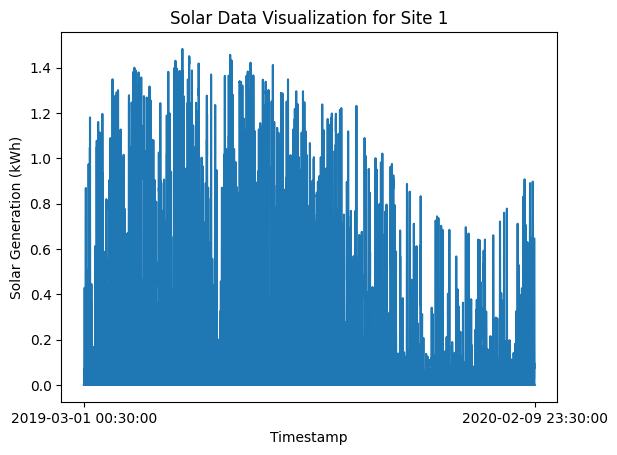

In [16]:
from datetime import datetime

# Adjust the plotting by start date, end date, and site number
def plot_solar_data_by_date(solar_data, site_id, start_date, end_date):
    site_data = solar_data[(solar_data['site_id'] == site_id) & 
                           (solar_data['timestamp_utc'] >= start_date) & 
                           (solar_data['timestamp_utc'] <= end_date)]
    plt.plot(site_data['timestamp_utc'], site_data['solar_gen_kwh'])
    plt.xlabel('Timestamp')
    plt.ylabel('Solar Generation (kWh)')
    plt.title(f'Solar Data Visualization for Site {site_id}')
    # plt.xticks([])
    plt.xticks([site_data['timestamp_utc'].iloc[0], site_data['timestamp_utc'].iloc[-1]], 
               [site_data['timestamp_utc'].iloc[0], site_data['timestamp_utc'].iloc[-1]], rotation=0)
    plt.show()

# Example usage
plot_solar_data_by_date(solar_data, site_id=1, start_date='2019-03-01', end_date='2020-02-10')

In [17]:
import ipywidgets as widgets
from IPython.display import display

# Function to update date pickers with earliest and latest dates
def update_date_pickers(button):
    site_id = site_dropdown.value
    site_data = solar_data[solar_data['site_id'] == site_id]
    start_date = site_data['timestamp_utc'].min()
    end_date = site_data['timestamp_utc'].max()
    start_date_picker.value = datetime.strptime(start_date, '%Y-%m-%d %H:%M:%S').date()
    end_date_picker.value = datetime.strptime(end_date, '%Y-%m-%d %H:%M:%S').date()

# Function to plot data based on selected site and date range
def plot_data(button):
    site_id = site_dropdown.value
    start_date = start_date_picker.value.strftime('%Y-%m-%d %H:%M:%S')
    end_date = end_date_picker.value.strftime('%Y-%m-%d %H:%M:%S')
    plot_solar_data_by_date(solar_data, site_id, start_date, end_date)

# Create widgets
site_dropdown = widgets.Dropdown(
    options=[('Site 1', 1), ('Site 2', 2), ('Site 3', 3), ('Site 4', 4)],
    description='Site:'
)
start_date_picker = widgets.DatePicker(description='Start Date')
end_date_picker = widgets.DatePicker(description='End Date')
update_button = widgets.Button(description='Update Dates')
plot_button = widgets.Button(description='Plot Data')

# Set button actions
update_button.on_click(update_date_pickers)
plot_button.on_click(plot_data)
# Clear the previous plot
output = widgets.Output()

with output:
    display(site_dropdown, start_date_picker, end_date_picker, update_button, plot_button)

# Display the output widget
display(output)


Output()

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/1087236573.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['timestamp_utc'] = pd.to_datetime(site_data['timestamp_utc'])
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/1087236573.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['timestamp_utc'] = pd.to_datetime(site_data['timestamp_utc'])
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/1087236573.py:7: SettingWithCopyWarning: 
A value 

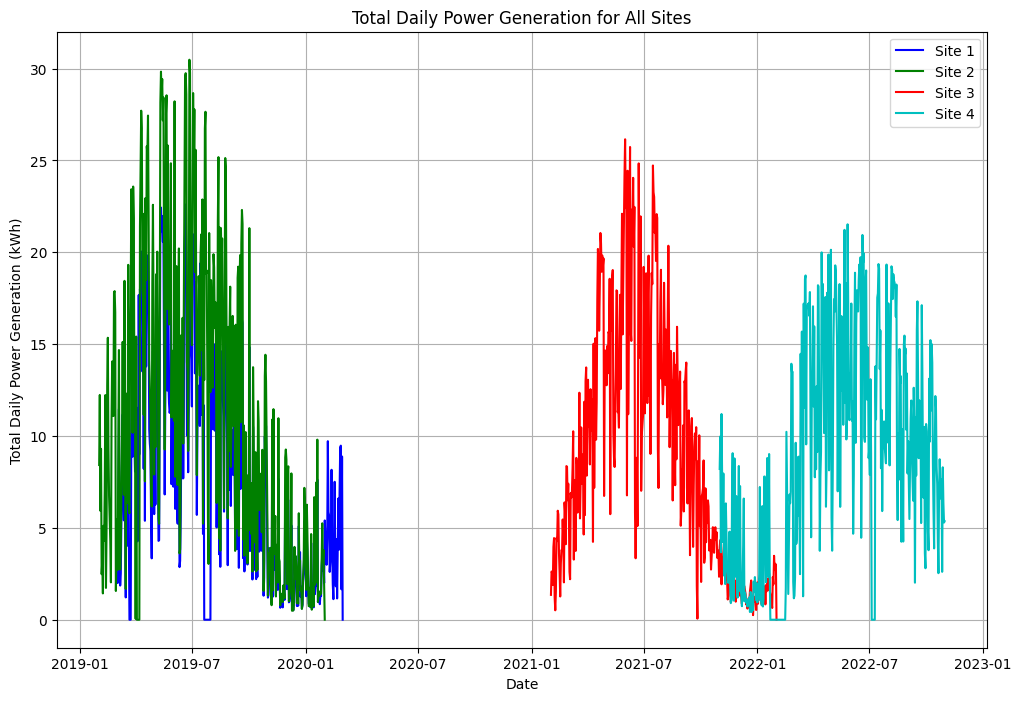

In [26]:
# Compute the sum of daily power generation
def plot_all_sites_daily_total_power_generation():
    plt.figure(figsize=(12, 8))
    colors = ['b', 'g', 'r', 'c']
    for site_number, color in zip(range(1, 5), colors):
        site_data = solar_data[solar_data['site_id'] == site_number]
        site_data['timestamp_utc'] = pd.to_datetime(site_data['timestamp_utc'])
        site_data.set_index('timestamp_utc', inplace=True)
        daily_total = site_data['solar_gen_kwh'].resample('D').sum()
        plt.plot(daily_total.index, daily_total.values, label=f'Site {site_number}', color=color)
    plt.xlabel('Date')
    plt.ylabel('Total Daily Power Generation (kWh)')
    plt.title('Total Daily Power Generation for All Sites')
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage
plot_all_sites_daily_total_power_generation()

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel

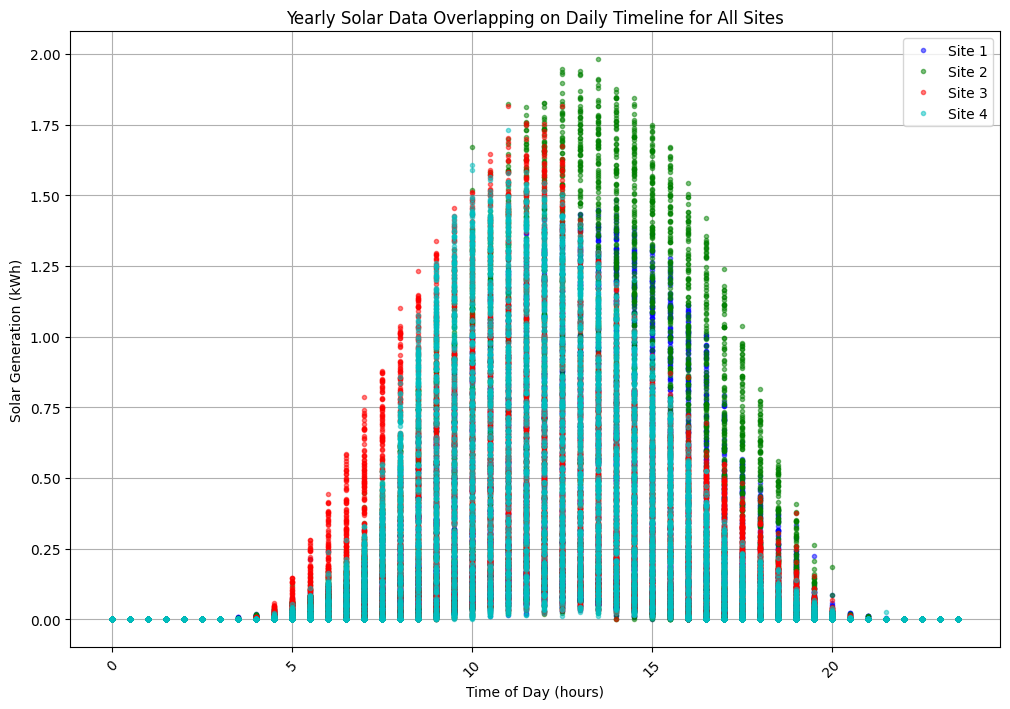

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60


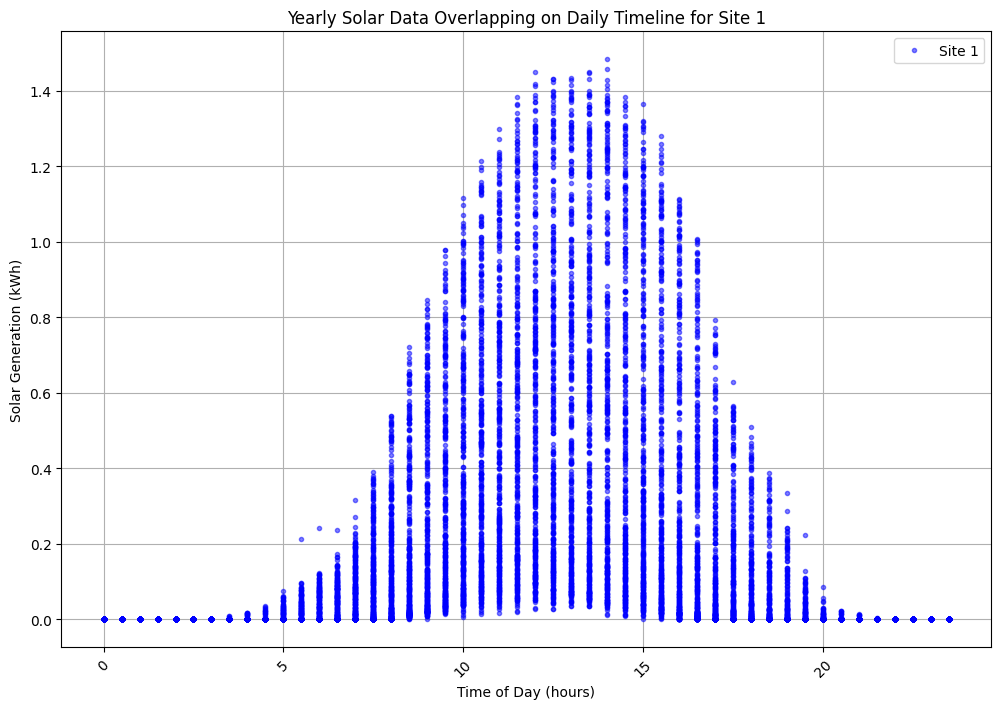

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60


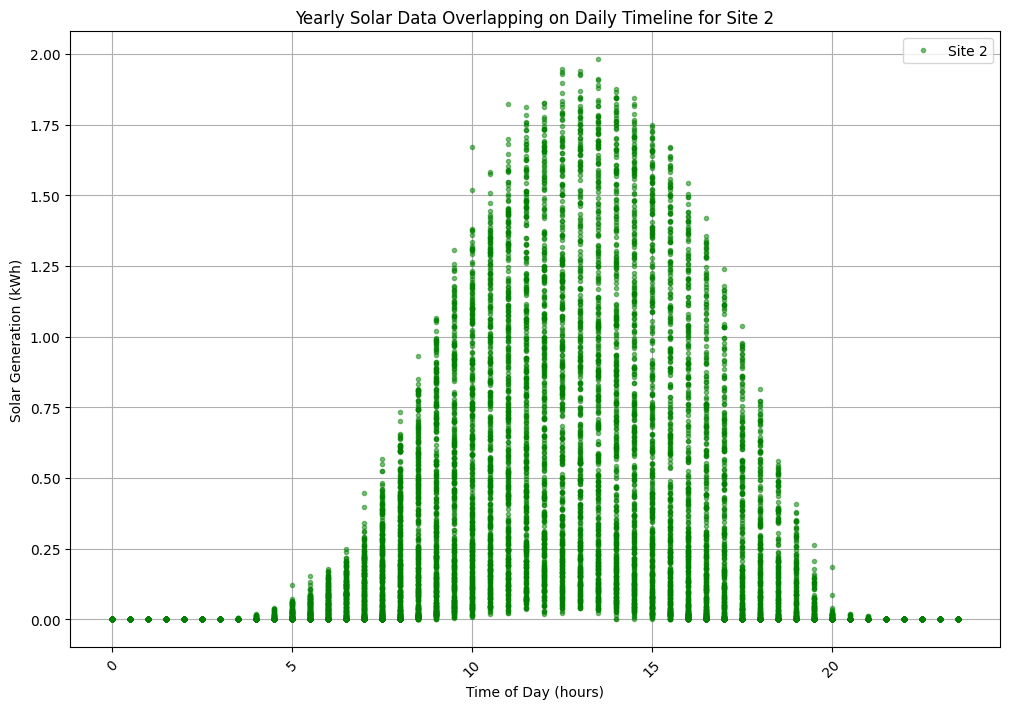

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60


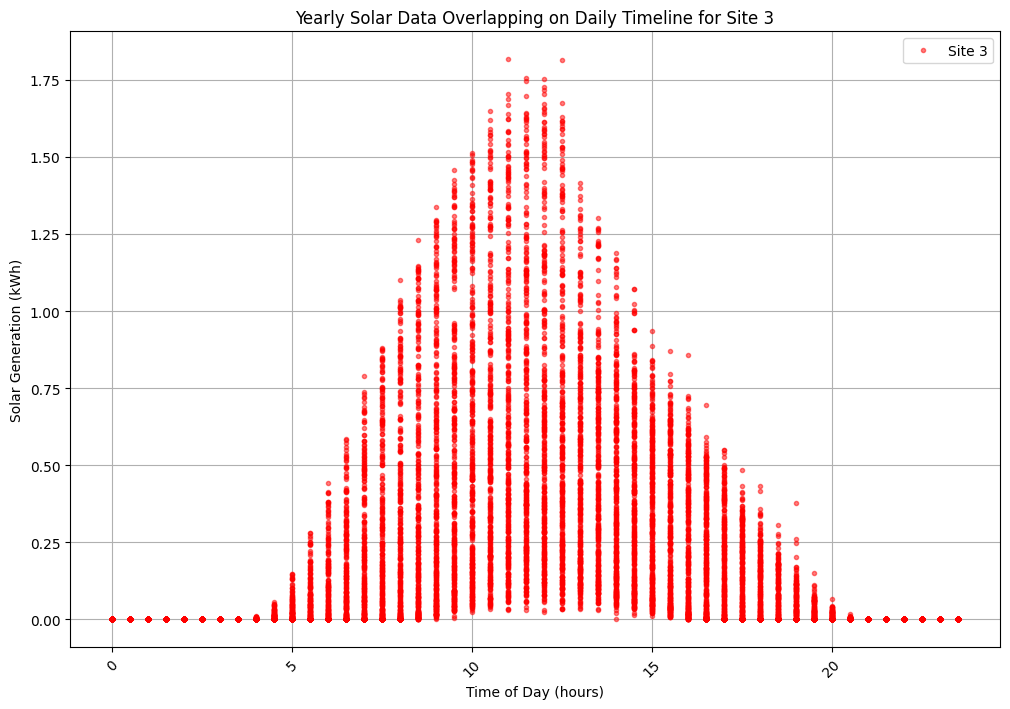

/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
/var/folders/rb/qt273dz13md9tmqc4k0h304w0000gn/T/ipykernel_8492/339109800.py:20: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60


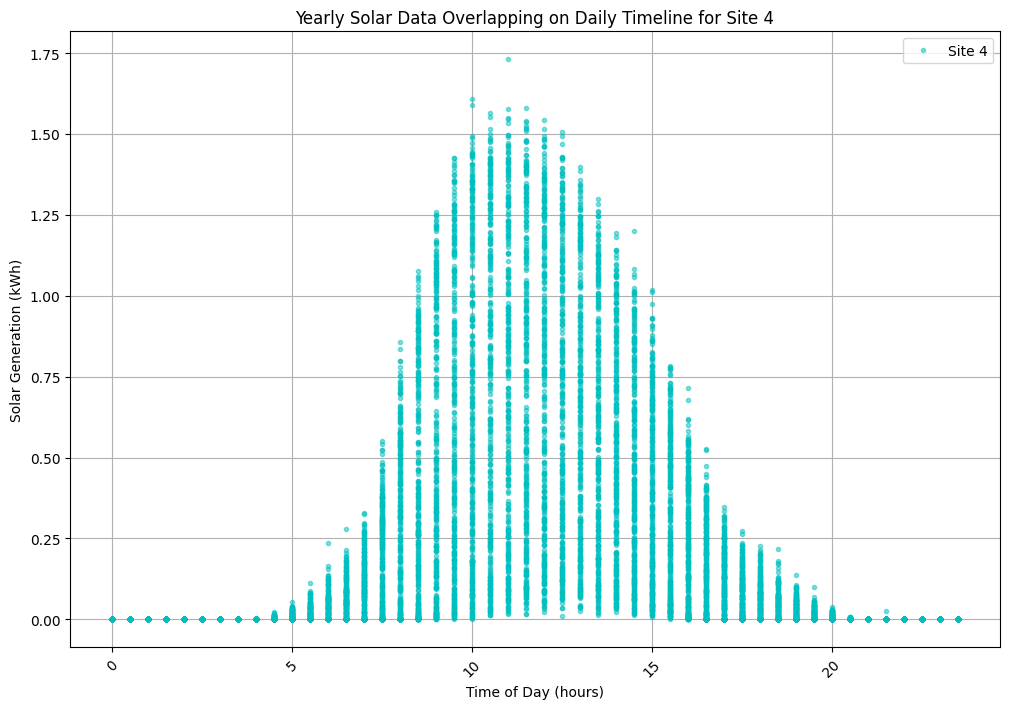

In [33]:
def plot_yearly_data_on_daily_timeline(solar_data, site_id=None):
    plt.figure(figsize=(12, 8))
    colors = ['b', 'g', 'r', 'c']
    if site_id is None:
        for site_id, color in zip(solar_data['site_id'].unique(), colors):
            site_data = solar_data[solar_data['site_id'] == site_id]
            site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
            site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60
            plt.plot(site_data['hour'], site_data['solar_gen_kwh'], '.', alpha=0.5, color=color, label=f'Site {site_id}')
        plt.xlabel('Time of Day (hours)')
        plt.ylabel('Solar Generation (kWh)')
        plt.title('Yearly Solar Data Overlapping on Daily Timeline for All Sites')
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.legend()
        plt.show()
    else:
        site_data = solar_data[solar_data['site_id'] == site_id]
        site_data['time'] = pd.to_datetime(site_data['timestamp_utc']).dt.time
        site_data['hour'] = pd.to_datetime(site_data['timestamp_utc']).dt.hour + pd.to_datetime(site_data['timestamp_utc']).dt.minute / 60
        plt.plot(site_data['hour'], site_data['solar_gen_kwh'], '.', alpha=0.5, color=colors[site_id-1], label=f'Site {site_id}')
        plt.xlabel('Time of Day (hours)')
        plt.ylabel('Solar Generation (kWh)')
        plt.title(f'Yearly Solar Data Overlapping on Daily Timeline for Site {site_id}')
        plt.xticks(rotation=45)
        plt.grid(True)
        plt.legend()
        plt.show()

# Example usage
plot_yearly_data_on_daily_timeline(solar_data)
for site_id in solar_data['site_id'].unique():
    plot_yearly_data_on_daily_timeline(solar_data, site_id)
